Loaded 37 JSE tickers across 2208 trading days.

--- Model Comparison: v1 (Rolling/Gross) vs v2 (Expanding/Net) ---
Metric                     | v1 (Rolling/Gross) | v2 (Expanding/Net)
Combined Mean IC           |            +0.0152 |            +0.0195
Annualized Return          |             20.09% |             20.34%
Annualized Volatility      |             39.71% |             38.36%
Sharpe Ratio               |               0.51 |               0.53
Avg Monthly Turnover       |              0.00% |             52.96%


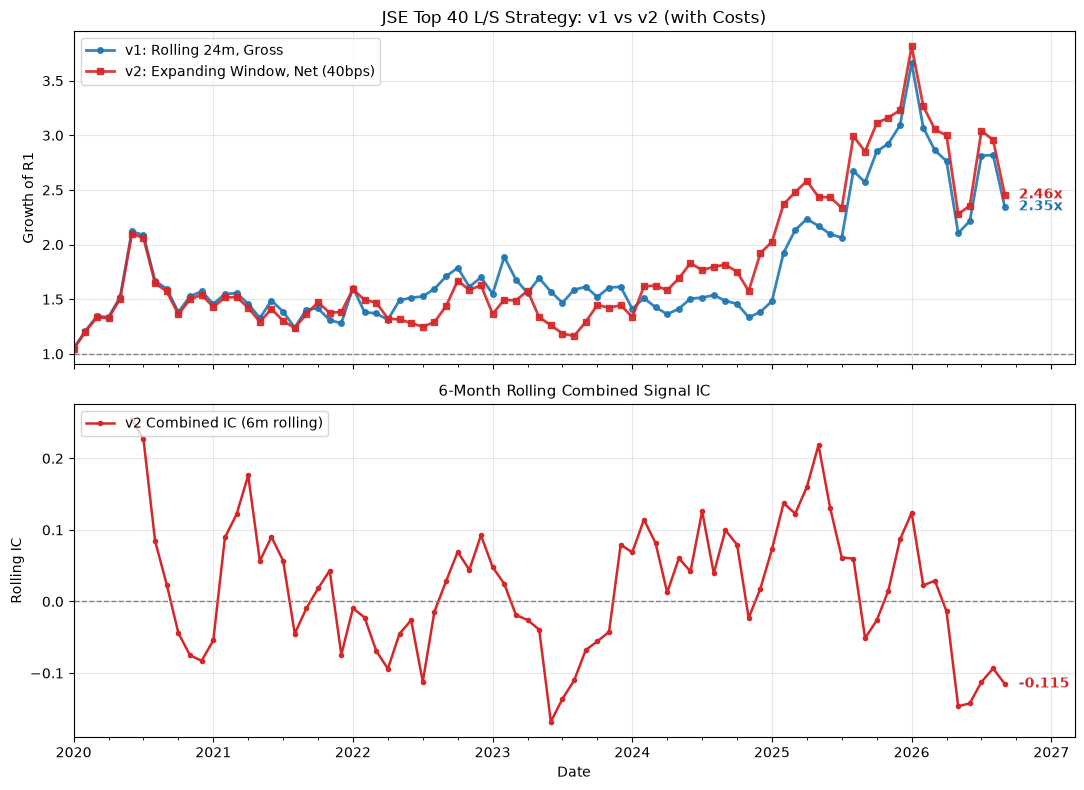

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("..")
from src.data_loader import fetch_jse_prices
from src.factors import compute_monthly_factors
from src.evaluation import compute_monthly_ic, walk_forward_ridge_backtest

# 1. Fetch clean JSE Top 40 historical prices
prices = fetch_jse_prices(start_date="2018-01-01", end_date="2026-11-01")
print(f"Loaded {prices.shape[1]} JSE tickers across {prices.shape[0]} trading days.\n")

# 2. Compute Global Z-Scored Factors (The baseline model)
factors = compute_monthly_factors(prices, neutralize=False)

# 3. Run Walk-Forward Backtest using Expanding Window + Transaction Costs
# We compare v1 (Rolling 24m, Gross) vs v2 (Expanding, Net of 40bps costs)
bt_rolling = walk_forward_ridge_backtest(
    factors, train_window=24, alpha=10.0, top_n=5, mode="rolling", cost_bps=0.0
)
bt_v2 = walk_forward_ridge_backtest(
    factors, train_window=24, alpha=50.0, top_n=5, mode="expanding", cost_bps=40.0
)

def _metrics(bt: pd.DataFrame, ret_col: str) -> tuple[float, float, float, pd.Series]:
    ann_return = bt[ret_col].mean() * 12
    ann_vol = bt[ret_col].std() * np.sqrt(12)
    sharpe = ann_return / ann_vol
    cum = (1 + bt[ret_col]).cumprod()
    return ann_return, ann_vol, sharpe, cum

r_ret, r_vol, r_sharpe, r_cum = _metrics(bt_rolling, "Gross_Return")
v2_ret, v2_vol, v2_sharpe, v2_cum = _metrics(bt_v2, "Net_Return")

print("--- Model Comparison: v1 (Rolling/Gross) vs v2 (Expanding/Net) ---")
print(f"{'Metric':<26s} | {'v1 (Rolling/Gross)':>18s} | {'v2 (Expanding/Net)':>18s}")
print(f"{'Combined Mean IC':<26s} | {bt_rolling['IC'].mean():>+18.4f} | {bt_v2['IC'].mean():>+18.4f}")
print(f"{'Annualized Return':<26s} | {r_ret:>18.2%} | {v2_ret:>18.2%}")
print(f"{'Annualized Volatility':<26s} | {r_vol:>18.2%} | {v2_vol:>18.2%}")
print(f"{'Sharpe Ratio':<26s} | {r_sharpe:>18.2f} | {v2_sharpe:>18.2f}")
print(f"{'Avg Monthly Turnover':<26s} | {0.0:>18.2%} | {bt_v2['Turnover'].mean():>18.2%}")

# 5. Plot both equity curves with markers and final-value data labels
os.makedirs("../results", exist_ok=True)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

# --- Plot 1: Cumulative Returns ---
# Add markers (o = circle, s = square) and slightly transparent lines
r_cum.plot(ax=ax1, label="v1: Rolling 24m, Gross", color="#1f77b4", linewidth=2, marker='o', markersize=4, alpha=0.9)
v2_cum.plot(ax=ax1, label="v2: Expanding Window, Net (40bps)", color="#d62728", linewidth=2, marker='s', markersize=4, alpha=0.9)
ax1.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax1.set_title("JSE Top 40 L/S Strategy: v1 vs v2 (with Costs)", fontsize=12)
ax1.set_ylabel("Growth of R1")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)

# Data Labels for final cumulative returns
ax1.annotate(f"{r_cum.iloc[-1]:.2f}x", 
             xy=(r_cum.index[-1], r_cum.iloc[-1]), 
             xytext=(10, 0), textcoords="offset points", 
             color="#1f77b4", fontweight="bold", fontsize=10, va="center")
             
ax1.annotate(f"{v2_cum.iloc[-1]:.2f}x", 
             xy=(v2_cum.index[-1], v2_cum.iloc[-1]), 
             xytext=(10, 0), textcoords="offset points", 
             color="#d62728", fontweight="bold", fontsize=10, va="center")

# --- Plot 2: Rolling IC ---
ic_v2 = bt_v2["IC"].rolling(6).mean()
ic_v2.plot(ax=ax2, label="v2 Combined IC (6m rolling)", color="#d62728", linewidth=1.8, marker='.', markersize=6)
ax2.axhline(0.0, color="gray", linestyle="--", linewidth=1)
ax2.set_title("6-Month Rolling Combined Signal IC", fontsize=11)
ax2.set_ylabel("Rolling IC")
ax2.legend(loc="upper left")
ax2.grid(alpha=0.3)

# Data Label for final IC value
ax2.annotate(f"{ic_v2.iloc[-1]:+.3f}", 
             xy=(ic_v2.index[-1], ic_v2.iloc[-1]), 
             xytext=(10, 0), textcoords="offset points", 
             color="#d62728", fontweight="bold", fontsize=10, va="center")

# Expand the x-axis limit slightly so the labels don't get cut off
ax1.set_xlim(right=r_cum.index[-1] + pd.DateOffset(months=6))
ax2.set_xlim(right=ic_v2.index[-1] + pd.DateOffset(months=6))

plt.tight_layout()
plt.savefig("../results/backtest_v2_final.png", dpi=150)
plt.show()